# Notebook 1 — Tái lập paper *High-Throughput Asset Pricing* (Chen & Dim)

**Mục tiêu:** hiểu từng bước của paper bằng cách tự chạy lại trên dữ liệu thật trong `data_raw/` — không dùng file dự báo dựng sẵn.

Ý tưởng của paper trong 5 dòng:

1. Có ~**136.000 chiến lược long–short** (kế toán, lợi suất quá khứ, chữ trong ticker), mỗi chiến lược có chuỗi lợi suất tháng.
2. Đứng **cuối năm Y-1**, lấy 20 năm lịch sử → tính **trung bình** và **t-stat** của từng chiến lược (IS).
3. Vì thử quá nhiều chiến lược, t-stat cao có thể chỉ là may mắn → dùng **Empirical Bayes (EB)**: học phân phối t-stat của cả họ chiến lược rồi **co (shrink)** từng chiến lược về mức hợp lý → ra **dự báo lợi suất năm Y**.
4. Đảo chiều chiến lược có dự báo âm, xếp hạng theo Sharpe dự báo, lấy **top 1% / 5% / 10%**.
5. Mở lợi suất thật của năm Y (OOS) để kiểm tra. Lặp lại cho Y = 1983…2020.

Notebook này **tự chạy** các bước 2–5 bằng Python thuần (không cần R). Phần EB dùng nghiệm giải tích thay cho tích phân số của code R gốc (kết quả tương đương, nhanh hơn nhiều).

In [1]:
import sys, pathlib, inspect, warnings
here = pathlib.Path.cwd()
for p in [here, *here.parents]:                    # tìm thư mục code/ chứa ht_common.py
    if (p / "ht_common.py").exists():
        sys.path.insert(0, str(p)); break
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
import statsmodels.formula.api as smf
import ht_common as h
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "font.size": 10})
pd.options.display.float_format = "{:,.3f}".format
print("RAW:", h.RAW, "| cache:", h.CACHE)

RAW: /home/phongndh/Documents/Paper/data_raw | cache: /home/phongndh/Documents/Paper/code/_cache


## 1. Dữ liệu: 6 họ chiến lược

Mỗi họ là một ma trận **chiến lược × tháng** (lợi suất long–short, đơn vị %/tháng). `EW` = trọng số bằng nhau, `VW` = trọng số theo vốn hóa. Hàm `load_wide` đọc 7 CSV trong `data_raw/` (lần đầu ~25 giây, sau đó cache) và áp dụng đúng bộ lọc của tác giả (past-return/ticker: giữ tháng có ≥2 cổ phiếu mỗi chân).

In [2]:
rows = []
for fam in h.FAMILIES:
    ids, wide = h.load_wide(fam)
    first = np.where(~np.isnan(wide).all(0))[0][[0, -1]]
    rows.append(dict(family=h.LONG_NAME[fam], n_strategies=len(ids), months=int((~np.isnan(wide)).sum()),
                     first=f"{1960 + first[0] // 12}-{first[0] % 12 + 1:02d}", last=f"{1960 + first[1] // 12}-{first[1] % 12 + 1:02d}"))
tab = pd.DataFrame(rows).set_index("family"); tab["n_strategies"] = tab.n_strategies.map("{:,}".format); tab["months"] = tab.months.map("{:,}".format)
display(tab); print("Tổng số chiến lược:", f"{sum(len(h.load_wide(f)[0]) for f in h.FAMILIES):,}", "(paper: 136.192 gồm cả 2 phiên bản EW/VW)")

,n_strategies,months,first,last
family,,,,
Accounting EW,"29,314","16,368,157",1960-01,2022-12
Accounting VW,"29,314","16,368,011",1960-01,2022-12
Past Return EW,"19,402","14,202,264",1962-01,2022-12
Past Return VW,"19,402","14,202,264",1962-01,2022-12
Ticker EW,"19,380","13,372,200",1963-01,2022-12
Ticker VW,"19,380","13,372,200",1963-01,2022-12


Tổng số chiến lược: 136,192 (paper: 136.192 gồm cả 2 phiên bản EW/VW)


## 2. Bước 1–2: thống kê trong mẫu (IS) và ngoài mẫu (OOS)

Ví dụ: dự báo **năm 2000** → IS = 20 năm 1980–1999, OOS = 2000. Chỉ giữ chiến lược có ≥ 36 tháng IS và đủ 12 tháng OOS (đúng luật của tác giả).  
`t-stat = mean / (std/√n)` (tương đương OLS `ret ~ 1` với sai số chuẩn HAC, maxlags = 0). Kiểm tra lại với `statsmodels`:

In [3]:
ids, wide = h.load_wide("ticker_ew")
st = h.rolling_stats(wide, 2000)
chk = []
for i in np.where(st["ok"])[0][[0, 500, 5000]]:
    d = pd.DataFrame({"ret": wide[i, (2000 - 20 - 1960) * 12:(2000 - 1960) * 12]}).dropna()
    m = smf.ols("ret ~ 1", d).fit(cov_type="HAC", cov_kwds={"maxlags": 0})
    chk.append(dict(signalid=ids[i], nobs=int(m.nobs), mean_IS=d.ret.mean(), tstat_statsmodels=m.tvalues["Intercept"], tstat_ours=st["tstat"][i], mean_OOS=st["mean_oos"][i]))
display(pd.DataFrame(chk))
print("Số chiến lược dùng được năm 2000 (ticker EW):", int(st["ok"].sum()), "/", len(ids))

,signalid,nobs,mean_IS,tstat_statsmodels,tstat_ours,mean_OOS
0,0,240,-0.001,-0.015,-0.015,0.181
1,500,240,0.038,0.545,0.545,0.284
2,5000,240,-0.002,-0.023,-0.023,-0.189


Số chiến lược dùng được năm 2000 (ticker EW): 19380 / 19380


## 3. Phân phối t-stat: dữ liệu vs. "nếu toàn là nhiễu"

Nếu mọi chiến lược chỉ là may rủi, t-stat ~ N(0,1) (đường đen). Phần dữ liệu **lệch ra ngoài** N(0,1) là chỗ có thể có thông tin thật. Paper dùng chính độ lệch này để ước lượng EB.

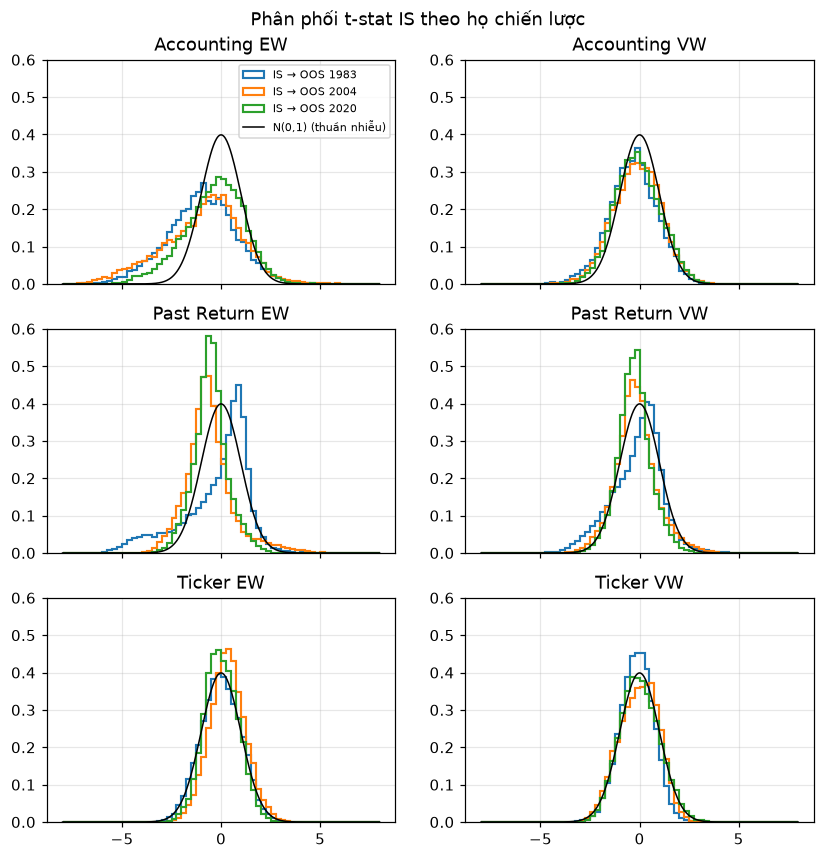

In [4]:
def tdist(fam, y):
    ids, wide = h.load_wide(fam); st = h.rolling_stats(wide, y); return st["tstat"][st["ok"]]

fig, axes = plt.subplots(3, 2, figsize=(9, 9), sharex=True)
for ax, fam in zip(axes.ravel(), h.FAMILIES):
    for y, c in ((1983, "tab:blue"), (2004, "tab:orange"), (2020, "tab:green")):
        ax.hist(tdist(fam, y), bins=np.linspace(-8, 8, 65), density=True, histtype="step", color=c, lw=1.4, label=f"IS → OOS {y}")
    x = np.linspace(-8, 8, 400); ax.plot(x, norm.pdf(x), "k", lw=1, label="N(0,1) (thuần nhiễu)")
    ax.set_title(h.LONG_NAME[fam]); ax.set_ylim(0, .6)
axes[0, 0].legend(fontsize=7); fig.suptitle("Phân phối t-stat IS theo họ chiến lược", y=.93); plt.show()

**Đọc hình:** Accounting EW lệch rõ nhất khỏi N(0,1) (đuôi t âm/dương dày) và Past-return EW cũng lệch; hai họ VW lệch ít hơn. **Ticker bám sát N(0,1)** — đúng là nhóm "đối chứng" của paper (chữ trong ticker không có lý do kinh tế để dự báo lợi suất). Lưu ý phân phối còn thay đổi theo thời gian (1983 / 2004 / 2020).

## 4. Bước 3: Empirical Bayes — lõi của paper

Mô hình: mỗi chiến lược có "hiệu quả thật" `θ` (đơn vị t-stat), ta chỉ thấy `t = θ + nhiễu`, nhiễu ~ N(0,1).  
Tác giả giả sử `θ` có **phân phối hỗn hợp 2 thành phần chuẩn** (`mixnorm`) và ước lượng 5 tham số bằng quasi-ML trên toàn bộ t-stat của họ trong năm đó. Khi đó `t` cũng là hỗn hợp chuẩn (phương sai `σ²+1`) và **E[θ | t] có công thức đóng** — code dưới đây:

In [5]:
print(inspect.getsource(h.eb_negloglik)); print(inspect.getsource(h.eb_posterior_mean))

def eb_negloglik(par, t):
    mua, sa, p, mub, sb = _unpack(par)
    lf = np.logaddexp(
        np.log(p) - 0.5 * np.log(2 * np.pi * (sa**2 + 1)) - 0.5 * (t - mua) ** 2 / (sa**2 + 1),
        np.log(1 - p) - 0.5 * np.log(2 * np.pi * (sb**2 + 1)) - 0.5 * (t - mub) ** 2 / (sb**2 + 1))
    return -np.sum(lf)

def eb_posterior_mean(par, t):
    """E[theta | t] for the fitted mixture prior (closed form, no numerical integration)."""
    mua, sa, p, mub, sb = _unpack(par)
    out_num, out_logw = [], []
    for w, mu, s in ((p, mua, sa), (1 - p, mub, sb)):
        v = s**2 + 1
        logw = np.log(w) - 0.5 * np.log(2 * np.pi * v) - 0.5 * (t - mu) ** 2 / v     # marginal density of t
        post_mean = mu + (s**2 / v) * (t - mu)                                          # E[theta|t, component]
        out_logw.append(logw); out_num.append(post_mean)
    lw = np.stack(out_logw); pm = np.stack(out_num)
    w = np.exp(lw - logsumexp(lw, axis=0))
    return (w * pm).sum(0)



Dự báo lợi suất tháng của chiến lược `i`: `pred_ret = θ̂_i × mean_IS_i / t_i` (đổi đơn vị t-stat về %/tháng). Ví dụ một họ–năm:

Accounting EW 2000: thành phần A: p=0.33, μ=0.08, σ=0.62 | thành phần B: μ=-1.44, σ=1.96


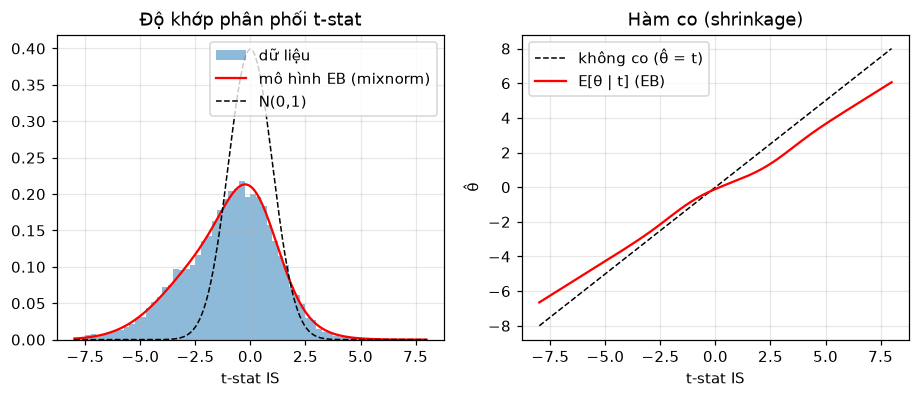

Co trung bình với |t|>2: 19.2%


In [6]:
fam, y = "acct_ew", 2000
ids, wide = h.load_wide(fam); st = h.rolling_stats(wide, y); t = st["tstat"][st["ok"]]
par = h.fit_eb(t); mua, sa, p, mub, sb = h._unpack(par)
print(f"{h.LONG_NAME[fam]} {y}: thành phần A: p={p:.2f}, μ={mua:.2f}, σ={sa:.2f} | thành phần B: μ={mub:.2f}, σ={sb:.2f}")
grid = np.linspace(-8, 8, 321); th = h.eb_posterior_mean(par, grid)
f_mix = (p * norm.pdf(grid, mua, np.sqrt(sa**2 + 1)) + (1 - p) * norm.pdf(grid, mub, np.sqrt(sb**2 + 1)))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(t, bins=np.linspace(-8, 8, 65), density=True, alpha=.5, label="dữ liệu"); ax[0].plot(grid, f_mix, "r", label="mô hình EB (mixnorm)"); ax[0].plot(grid, norm.pdf(grid), "k--", lw=1, label="N(0,1)")
ax[0].set_title("Độ khớp phân phối t-stat"); ax[0].legend(); ax[0].set_xlabel("t-stat IS")
ax[1].plot(grid, grid, "k--", lw=1, label="không co (θ̂ = t)"); ax[1].plot(grid, th, "r", label="E[θ | t] (EB)")
ax[1].set_title("Hàm co (shrinkage)"); ax[1].set_xlabel("t-stat IS"); ax[1].set_ylabel("θ̂"); ax[1].legend(); plt.show()
big = np.abs(t) > 2; print("Co trung bình với |t|>2:", f"{1 - np.mean(h.eb_posterior_mean(par, t[big]) / t[big]):.1%}")

## 5. Bước 4–5: dựng bảng dự báo cho mọi họ × mọi năm 1983–2020

`build_panel` lặp: (a) thống kê IS/OOS từng năm, (b) fit EB trên t-stat IS của họ, (c) tính `pred_ret`. Kết quả: mỗi dòng = **một chiến lược × một năm dự báo** (4,9 triệu dòng). Lần đầu ~3 phút, sau đó đọc cache.

In [7]:
f = h.CACHE / "panel_eb.parquet"
if f.exists():
    P = pd.read_parquet(f)
else:
    P = h.build_all_panels(); P.to_parquet(f)
print(P.shape); display(P.sample(5, random_state=0))
# kiểm tra không rò rỉ: IS luôn kết thúc trước năm OOS
assert (P.oos_year.between(1983, 2020)).all()
print("Số chiến lược dùng được mỗi năm (trung bình):"); display(P.groupby("family").size().div(P.oos_year.nunique()).round(0).to_frame("n/year"))

(4856694, 10)


,family,signalid,oos_year,mean_is,tstat,nobs,sd_is,thetahat,pred_ret,mean_oos
4175608,ticker_vw,16594,1985,-0.329,-1.683,144,2.349,-0.097,-0.019,1.729
286500,acct_ew,13210,1995,0.078,0.684,240,1.760,0.154,0.017,0.069
1464915,acct_vw,2640,2004,0.009,0.060,240,2.219,0.012,0.002,0.118
1608213,acct_vw,15238,2009,-0.024,-0.174,240,2.134,-0.100,-0.014,-0.049
1997862,past_ret_ew,10992,1987,-0.066,-0.655,240,1.550,-0.292,-0.029,0.020


Số chiến lược dùng được mỗi năm (trung bình):


,n/year
family,
acct_ew,"25,122.000"
acct_vw,"25,122.000"
past_ret_ew,"19,402.000"
past_ret_vw,"19,402.000"
ticker_ew,"19,380.000"
ticker_vw,"19,380.000"


### 5a. Dự báo EB có bám lợi suất thật không? (cf. Hình 4–5 của paper)
Mỗi năm chia chiến lược của họ thành 20 nhóm theo lợi suất IS; so **IS** (tím đứt), **dự báo EB** (đỏ) và **OOS thực** (xanh). Đơn vị %/năm.

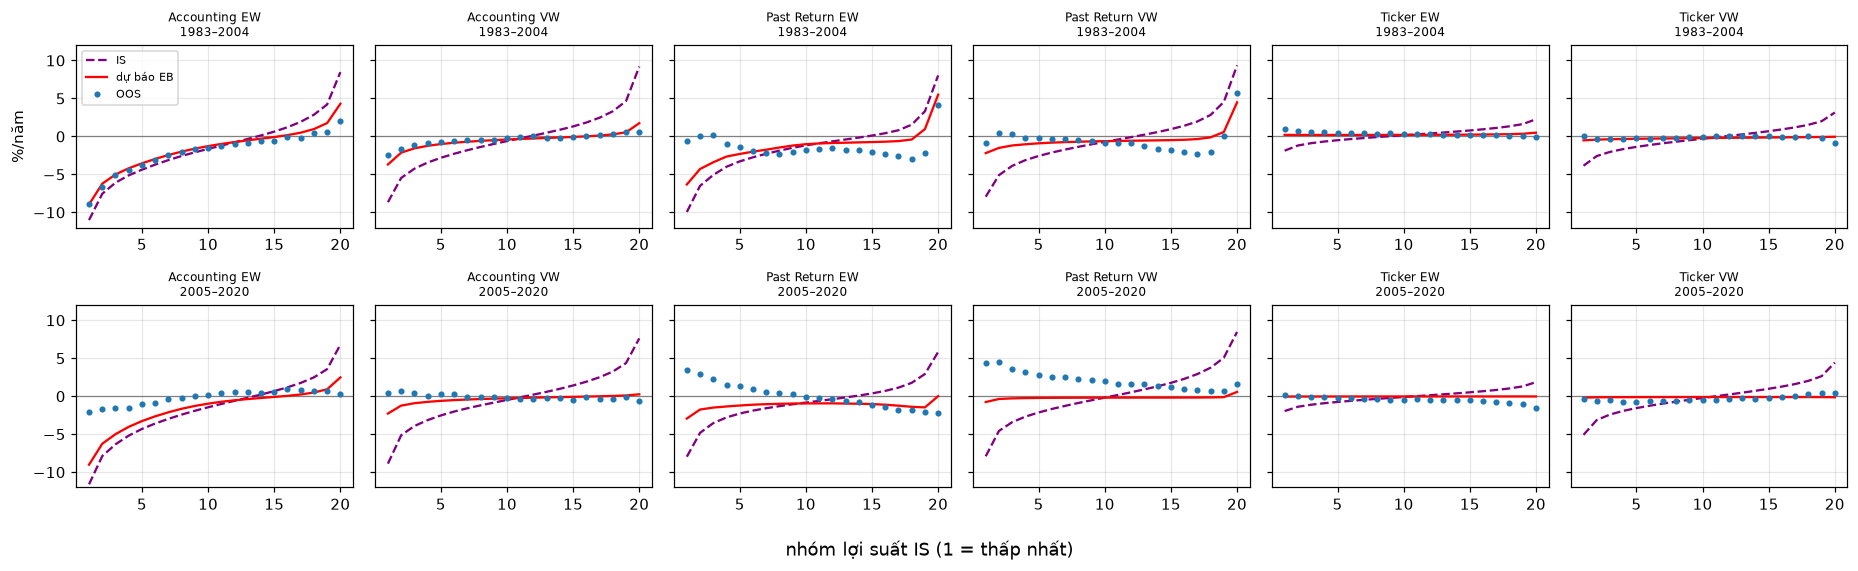

In [8]:
def bins_table(P, y0, y1, q=20):
    d = P[(P.oos_year >= y0) & (P.oos_year <= y1)].copy()
    d["bin"] = d.groupby(["family", "oos_year"]).mean_is.transform(lambda x: pd.qcut(x, q, labels=False, duplicates="drop"))
    g = d.groupby(["family", "oos_year", "bin"])[["mean_is", "mean_oos", "pred_ret"]].mean().groupby(["family", "bin"]).mean() * 12
    return g

fig, axes = plt.subplots(2, 6, figsize=(17, 5.2), sharey=True)
for r, (y0, y1) in enumerate(((1983, 2004), (2005, 2020))):
    g = bins_table(P, y0, y1)
    for c, fam in enumerate(h.FAMILIES):
        a = axes[r, c]; d = g.loc[fam]
        a.axhline(0, c="grey", lw=.8); a.plot(d.index + 1, d.mean_is, "--", c="purple", label="IS"); a.plot(d.index + 1, d.pred_ret, c="red", label="dự báo EB"); a.plot(d.index + 1, d.mean_oos, "o", c="tab:blue", ms=3, label="OOS")
        a.set_title(f"{h.LONG_NAME[fam]}\n{y0}–{y1}", fontsize=8); a.set_ylim(-12, 12)
axes[0, 0].legend(fontsize=7); axes[0, 0].set_ylabel("%/năm"); fig.supxlabel("nhóm lợi suất IS (1 = thấp nhất)"); plt.tight_layout(); plt.show()

**Đọc hình:** trước 2004 dự báo EB (đỏ) bám OOS (chấm xanh) khá sát ở Accounting EW và hai họ Past-return; sau 2005 dự báo EB **quá lạc quan** ở Accounting EW (OOS phẳng hơn nhiều), và ở **Past-return OOS đảo dấu** (nhóm IS cao lại có OOS thấp, và ngược lại). Ticker phẳng ≈ 0 ở cả hai giai đoạn. Đây là động lực để thử mô hình/hiệu chỉnh *thích nghi theo thời gian* ở notebook 2.

## 6. Bước 4–5: chọn chiến lược và kiểm tra tương lai (cf. Bảng 2)

Luật chọn của paper, mỗi năm, **gộp cả 6 họ**:
- **EB mining:** đảo chiều chiến lược nếu `pred_ret < 0`; xếp hạng theo Sharpe dự báo `θ̂/√n`; lấy top 1/5/10%.
- **Naive mining:** đảo chiều theo dấu `t-stat`; xếp hạng theo `|t-stat|` (không dùng EB).
- Danh mục = trung bình **trọng số bằng nhau** của các chiến lược được chọn; đo bằng lợi suất tháng thật của năm OOS.

In [9]:
print(inspect.getsource(h.monthly_top_returns))
sign_eb = np.where(P.pred_ret >= 0, 1.0, -1.0); sra = P.thetahat.values / np.sqrt(P.nobs.values) * sign_eb
sign_t = np.where(P.tstat >= 0, 1.0, -1.0)
mr_eb = h.monthly_top_returns(P, sra, sign_eb)
mr_nv = h.monthly_top_returns(P, P.tstat.values * sign_t, sign_t)

def monthly_top_returns(panel, score, sign, ranks=(1, 5, 10)):
    """Paper's selection rule. Per oos_year, across ALL families pooled:
    orient each strategy by `sign` (+1 keep, -1 flip long/short), rank by the oriented `score` (percentile),
    keep the top r%, return the equal-weighted monthly OOS return of that portfolio.
    panel must have columns family, signalid, oos_year. score/sign are arrays aligned with panel rows.
    """
    sign = np.asarray(sign, float)
    R = signed_monthly_returns(panel, sign)
    pct = pd.Series(np.asarray(score, float)).groupby(panel.oos_year.values).rank(pct=True).values * 100
    years = panel.oos_year.values
    out = []
    for y in np.unique(years):
        m = years == y
        for r in ranks:
            sel = m & (pct >= 100 - r)
            out.append(pd.DataFrame(dict(year=y, month=np.arange(1, 13), rank=r,
                                         ret=np.nanmean(R[sel], 0), nstrat=int(sel.sum()))))
    return pd.concat(out, ignore_inde

In [10]:
def fmt(s, name):
    s = s.copy(); s.index = [f"{name} top {r}%" for r in s.index]; return s
full = pd.concat([fmt(h.summarize(mr_eb), "EB"), fmt(h.summarize(mr_nv), "Naive")])
full.columns = ["# chiến lược", "Lợi suất TB (%/năm)", "t-stat", "Sharpe (năm)"]
print("Giai đoạn 1983–2020"); display(full.round(2))
paper = pd.DataFrame({"Paper: lợi suất (%/năm)": [5.70, 5.72], "Paper: Sharpe": [1.46, 1.45],
                      "Notebook: lợi suất": [full.iloc[0, 1], full.iloc[3, 1]], "Notebook: Sharpe": [full.iloc[0, 3], full.iloc[3, 3]]}, index=["EB top 1%", "Naive top 1%"])
print("Đối chiếu số paper công bố (Bảng 2):"); display(paper.round(2))

Giai đoạn 1983–2020


,# chiến lược,Lợi suất TB (%/năm),t-stat,Sharpe (năm)
EB top 1%,"1,278.710",5.790,9.170,1.490
EB top 5%,"6,390.950",3.990,8.150,1.320
EB top 10%,"12,783.760",2.820,7.180,1.170
Naive top 1%,"1,278.710",5.730,8.910,1.450
Naive top 5%,"6,390.950",3.720,7.730,1.250
Naive top 10%,"12,781.390",2.610,6.760,1.100


Đối chiếu số paper công bố (Bảng 2):


,Paper: lợi suất (%/năm),Paper: Sharpe,Notebook: lợi suất,Notebook: Sharpe
EB top 1%,5.700,1.460,5.790,1.490
Naive top 1%,5.720,1.450,5.730,1.450


Số của notebook **rất sát paper** (naive gần như trùng; EB lệch nhỏ vì ta fit EB bằng Nelder–Mead nhiều điểm xuất phát còn tác giả dùng BOBYQA một điểm, cùng dữ liệu). Hai kết luận của paper tái hiện được: (1) chọn từ quá khứ vẫn có lợi suất OOS dương; (2) **EB ≈ naive ở top 1%** — giá trị của EB nằm nhiều hơn ở ước lượng *mức* lợi suất.

In [11]:
# chia giai đoạn như paper: trước / sau 2004
parts = []
for lo, hi in ((1983, 2004), (2005, 2020)):
    a = pd.concat([fmt(h.summarize(mr_eb, lo, hi), "EB"), fmt(h.summarize(mr_nv, lo, hi), "Naive")])[["mean_ann", "sharpe"]].T
    a.index = [f"{lo}–{hi}: " + i for i in ("lợi suất %/năm", "Sharpe")]; parts.append(a)
display(pd.concat(parts).round(2))

,EB top 1%,EB top 5%,EB top 10%,Naive top 1%,Naive top 5%,Naive top 10%
1983–2004: lợi suất %/năm,8.340,5.670,4.250,8.350,5.490,3.960
1983–2004: Sharpe,1.930,1.640,1.530,1.900,1.640,1.460
2005–2020: lợi suất %/năm,2.290,1.680,0.860,2.110,1.280,0.740
2005–2020: Sharpe,0.780,0.790,0.510,0.710,0.590,0.440


### 6a. Đối chiếu với các predictor đã công bố (Panel C của Bảng 2)
Trung bình lợi suất long–short của các predictor học thuật (Chen–Zimmermann, `data_bo_sung/`) trong cùng giai đoạn: *Pub Anytime* = công bố đến 2020, *Pub Pre-2004* = công bố trước 2004.

In [12]:
pub = pd.read_csv(h.ROOT / "data_bo_sung" / "PredictorLSretWide-feds-2021037.csv"); pub["date"] = pd.to_datetime(pub["date"])
doc = pd.read_csv(h.ROOT / "data_bo_sung" / "signaldocumentation-BasicInfo.csv")[["Acronym", "Year"]].drop_duplicates("Acronym")
pub = pub[(pub.date.dt.year >= 1983) & (pub.date.dt.year <= 2020)].set_index("date")
yr = doc.set_index("Acronym").Year
rows = {}
for name, maxy in (("Pub Anytime", 2020), ("Pub Pre-2004", 2004)):
    cols = [c for c in pub.columns if c in yr.index and yr[c] <= maxy]
    r = pub[cols].mean(1); rows[name] = dict(nstrat=pub[cols].notna().sum(1).mean(), mean_ann=r.mean() * 12, tstat=r.mean() / r.std() * np.sqrt(len(r)), sharpe=r.mean() / r.std() * np.sqrt(12))
pubtab = pd.DataFrame(rows).T; pubtab.columns = ["# chiến lược", "Lợi suất TB (%/năm)", "t-stat", "Sharpe (năm)"]
display(pd.concat([full.iloc[[0, 1, 2]], full.iloc[[3, 4, 5]], pubtab]).round(2))

,# chiến lược,Lợi suất TB (%/năm),t-stat,Sharpe (năm)
EB top 1%,"1,278.710",5.790,9.170,1.490
EB top 5%,"6,390.950",3.990,8.150,1.320
EB top 10%,"12,783.760",2.820,7.180,1.170
Naive top 1%,"1,278.710",5.730,8.910,1.450
Naive top 5%,"6,390.950",3.720,7.730,1.250
Naive top 10%,"12,781.390",2.610,6.760,1.100
Pub Anytime,197.680,6.030,12.820,2.080
Pub Pre-2004,82.330,5.610,10.000,1.620


## 7. Ticker có chiếm tỉ lệ nhỏ trong top chiến lược không? (cf. Bảng 3)

Với mỗi năm, lấy top 1/5/10% theo EB (hoặc naive) và đếm tỉ lệ thuộc từng họ.

In [13]:
def composition(P, score, ranks=(1, 5, 10)):
    pct = pd.Series(score).groupby(P.oos_year.values).rank(pct=True).values * 100
    out = {}
    for r in ranks:
        out[f"top {r}%"] = P.family[pct >= 100 - r].value_counts(normalize=True) * 100
    return pd.DataFrame(out).reindex(h.FAMILIES).fillna(0).rename(index=h.LONG_NAME)
print("Theo EB (1983–2020), % số chiến lược được chọn:"); display(composition(P, sra).round(1))
print("Theo Naive:"); display(composition(P, np.abs(P.tstat.values)).round(1))

Theo EB (1983–2020), % số chiến lược được chọn:


,top 1%,top 5%,top 10%
family,,,
Accounting EW,92.600,84.600,78.600
Accounting VW,0.300,1.000,4.800
Past Return EW,7.000,12.600,12.900
Past Return VW,0.100,1.800,3.300
Ticker EW,0.000,0.000,0.300
Ticker VW,0.000,0.000,0.000


Theo Naive:


,top 1%,top 5%,top 10%
family,,,
Accounting EW,84.700,65.900,51.600
Accounting VW,1.600,8.300,13.600
Past Return EW,12.600,17.500,18.000
Past Return VW,1.100,5.500,8.600
Ticker EW,0.000,1.600,4.300
Ticker VW,0.100,1.200,3.900


**Kết luận về ticker:** trong top 1% theo EB, **Ticker EW và Ticker VW đều ≈ 0%**, còn Accounting EW chiếm đa số (paper: 91,0%) — tái hiện đúng. Ticker chỉ bắt đầu xuất hiện khi nới tới top 10% và với naive mining (vì |t| cao do may mắn). EB nhận ra phần lớn t-stat cao của ticker là nhiễu nên co mạnh chúng về 0.

## 8. Lợi suất tích lũy OOS của các danh mục

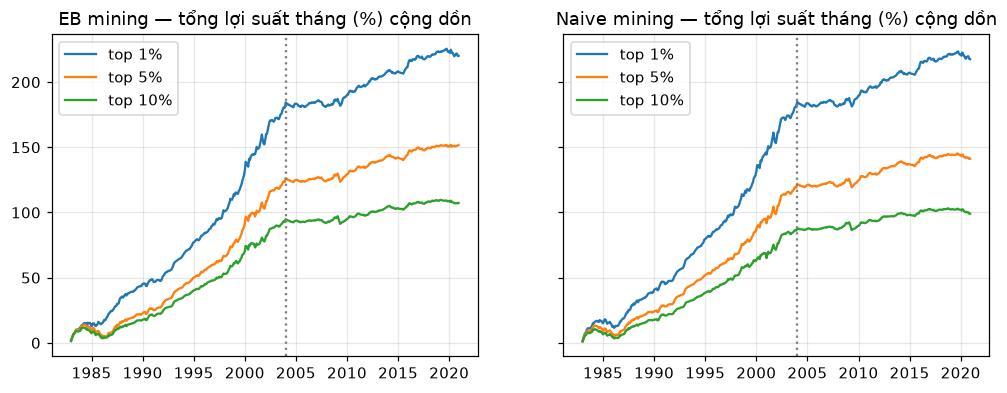

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, (mr, nm) in zip(ax, ((mr_eb, "EB"), (mr_nv, "Naive"))):
    for r in (1, 5, 10):
        d = mr[mr["rank"] == r].sort_values(["year", "month"]); a.plot(np.arange(len(d)) / 12 + 1983, d.ret.cumsum() , label=f"top {r}%")
    a.set_title(f"{nm} mining — tổng lợi suất tháng (%) cộng dồn"); a.axvline(2004, c="grey", ls=":"); a.legend()
plt.show()

## 9. Tóm tắt & những gì cần nhớ

- **Dữ liệu vào:** chuỗi lợi suất tháng của 136k chiến lược (không phải giá cổ phiếu). **Dự báo:** lợi suất trung bình năm sau của từng chiến lược.
- **EB** = học phân phối t-stat của cả họ → co các t-stat cực đoan. Tái hiện: EB top 1% ≈ 5,8%/năm, Sharpe ≈ 1,5; naive ≈ 5,7%/năm, Sharpe ≈ 1,45 (paper: 5,70 / 1,46 và 5,72 / 1,45).
- **Thông tin dự báo tập trung ở kế toán EW**; ticker ≈ 0% trong top 1%.
- **Giới hạn của mốc này** (cơ hội cho notebook 2): hiệu quả sụt mạnh sau 2004; xếp hạng dựa trên **một** số (t-stat/EB) và danh mục **trọng số bằng nhau** nên các chiến lược gần như trùng nhau (cùng biến kế toán) bị đếm nhiều lần.

→ Tiếp: `02_new_idea_ai_walkforward.ipynb`.